## Who patents?

   Category  Unique_IDs
INDIVIDUALS        2287

           Type  Unique_Entities
        COMPANY             1246
     UNIVERSITY              479
 GOV NON-PROFIT              165
      UNCERTAIN                1
UNIQUE ENTITIES             1880

                       Type  Families
                    COMPANY      7944
                 UNIVERSITY      2337
             GOV NON-PROFIT       559
       COMPANY + INDIVIDUAL       548
                 INDIVIDUAL       415
       COMPANY + UNIVERSITY       303
GOV NON-PROFIT + UNIVERSITY       136
    INDIVIDUAL + UNIVERSITY       132
       Other Collaborations       222
             TOTAL FAMILIES     12596


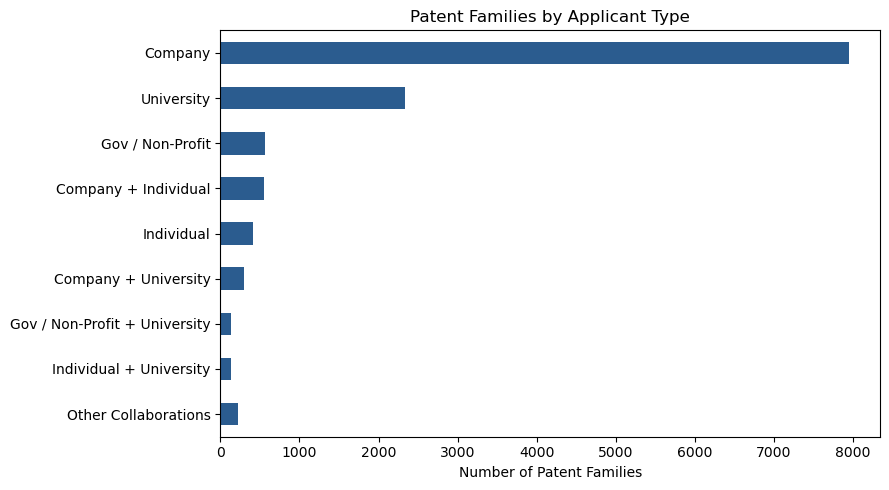

In [1]:
import matplotlib.pyplot as plt
import pandas as pd


def summarize_individuals(df: pd.DataFrame):
  ind_df = df[df["psn_sector_imputed"] == "INDIVIDUAL"]
  summary = pd.DataFrame([{
      "Category": "INDIVIDUALS",
      "Unique_IDs": ind_df["psn_id"].nunique(),
      
  }])
  print(summary.to_string(index=False))
  return summary


def summarize_entities(df: pd.DataFrame):
  inst_df = df[df["psn_sector_imputed"] != "INDIVIDUAL"]
  summary = (
      inst_df.groupby("psn_sector_imputed")["harmonized_name_final"]
      .nunique()
      .sort_values(ascending=False)
      .rename_axis("Type")
      .reset_index(name="Unique_Entities")
  )
  total = pd.DataFrame([{
      "Type": "UNIQUE ENTITIES",
      "Unique_Entities": df["harmonized_name_final"].nunique(),
  }])
  summary = pd.concat([summary, total], ignore_index=True)
  print("\n" + summary.to_string(index=False))
  return summary


def summarize_families(df: pd.DataFrame, top_n: int = 8):
  fam_types = df.groupby("docdb_family_id")["psn_sector_imputed"].apply(
      lambda s: " + ".join(sorted(s.dropna().unique()))
  )
  summary = (
      fam_types.value_counts().rename_axis("Type").reset_index(name="Families")
  )
  if len(summary) > top_n:
    other = pd.DataFrame([{
        "Type": "Other Collaborations",
        "Families": summary.iloc[top_n:]["Families"].sum(),
    }])
    summary = pd.concat([summary.iloc[:top_n], other], ignore_index=True)

  total = pd.DataFrame(
      [{"Type": "TOTAL FAMILIES", "Families": df["docdb_family_id"].nunique()}]
  )
  summary = pd.concat([summary, total], ignore_index=True)
  print("\n" + summary.to_string(index=False))
  return summary


def plot_applicant_types(families_summary: pd.DataFrame):
  plot_df = families_summary[
      families_summary["Type"] != "TOTAL FAMILIES"
  ].iloc[::-1]

  ax = plot_df.plot.barh(
      x="Type",
      y="Families",
      legend=False,
      color="#2b5c8f",
      figsize=(9, 5),
      title="Patent Families by Applicant Type",
  )
  ax.set_yticklabels(
      plot_df["Type"]
      .str.title()
      .str.replace("Gov Non-Profit", "Gov / Non-Profit")
  )
  ax.set_xlabel("Number of Patent Families")
  ax.set_ylabel("")
  plt.tight_layout()
  plt.show()


# Execution
df_completo = pd.read_csv("harmonization_output.csv")
ind_summary = summarize_individuals(df_completo)
ent_summary = summarize_entities(df_completo)
fam_summary = summarize_families(df_completo)
plot_applicant_types(fam_summary)

In [2]:
import pandas as pd

df = pd.read_csv("harmonization_output.csv")
uncertain = df[df["psn_sector_imputed"] == "UNCERTAIN"]

print(
    uncertain[
        [
            "docdb_family_id",
            "psn_id",
            "psn_name",
            "psn_sector",
            "harmonized_name_final",
        ]
    ].to_string(index=False)
)

 docdb_family_id   psn_id                                           psn_name psn_sector                         harmonized_name_final
        47633176  6733642 DHITECH - DISTRETTO TECNOLOGICO H IGH TECH S.C.A.R    UNKNOWN DHITECH DISTRETTO TECNOLOGICO H IGH TECH SCAR
        75847816 23866221                                    -NOT AVAILABLE-    UNKNOWN                                           NaN
        72337285 23866221                                    -NOT AVAILABLE-    UNKNOWN                                           NaN
        77951540 23866221                                    -NOT AVAILABLE-    UNKNOWN                                           NaN
        77614144 23866221                                    -NOT AVAILABLE-    UNKNOWN                                           NaN
        89119526 23866221                                    -NOT AVAILABLE-    UNKNOWN                                           NaN
        79268295 23866221                                    -

## Concentration

In [3]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # Lotka regression and Kendall's tau
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }



In [4]:
def compute_concentration_table(df_completo: pd.DataFrame) -> pd.DataFrame:
    # Define sector subsets
    groups = {
        "All Entities": df_completo,
        "Companies": df_completo[df_completo["psn_sector_imputed"] == "COMPANY"],
        "Universities": df_completo[df_completo["psn_sector_imputed"] == "UNIVERSITY"],
        "Gov / Non-Profit": df_completo[df_completo["psn_sector_imputed"] == "GOV NON-PROFIT"],
        "Institutional": df_completo[df_completo["psn_sector_imputed"] != "INDIVIDUAL"],
    }

    # Compute six concentration measures per group using distinct patent families per entity
    return pd.DataFrame.from_dict(
        {k: six_measures(v.groupby("harmonized_name_final")["docdb_family_id"].nunique().values) for k, v in groups.items()},
        orient="index",
    )
concentration_table = compute_concentration_table(df_completo)
print(concentration_table.to_string())

                  firms  patents (sum over firms)        CV    CR4 (%)    CR8 (%)        HH       1/HH   Lotka L  Lotka p-value      Gini
All Entities       1880                     14325  4.552883  16.251309  22.443281  0.011552  86.565257 -1.043151   2.366821e-27  0.767153
Companies          1246                     10116  5.119841  23.013049  31.781336  0.021823  45.822742 -0.874426   4.095283e-20  0.799586
Universities        479                      3279  1.982065  12.168344  20.829521  0.010272  97.350183 -1.107575   9.968913e-17  0.681719
Gov / Non-Profit    165                       947  1.973574  27.349525  40.760296  0.029524  33.871247 -0.964876   6.603107e-10  0.663953
Institutional      1880                     14325  4.552883  16.251309  22.443281  0.011552  86.565257 -1.043151   2.366821e-27  0.767153


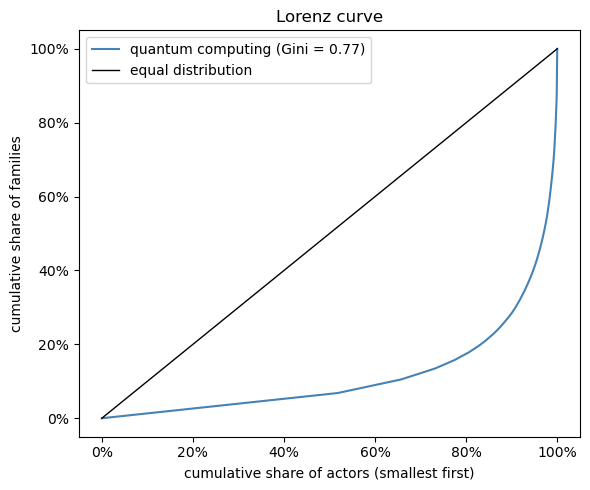

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Compute distinct families per actor across the entire dataset
x_all = (
    df_completo.groupby("harmonized_name_final")["docdb_family_id"]
    .nunique()
    .values
)

fig, ax = plt.subplots(figsize=(6, 5))

# Lorenz curve and Gini index
share_of_firms, share_of_patents = lorenz_curve(x_all)
ax.plot(
    share_of_firms,
    share_of_patents,
    color="steelblue",
    label=f"quantum computing (Gini = {gini(x_all):.2f})",
)
ax.plot([0, 1], [0, 1], color="black", lw=1, label="equal distribution")
ax.set(
    title="Lorenz curve",
    xlabel="cumulative share of actors (smallest first)",
    ylabel="cumulative share of families",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()

plt.tight_layout()
plt.show()

## Consolidate

In [10]:
import numpy as np
import pandas as pd

SPLIT_YEAR = 2015
MIN_FAMILIES = 2

# Filter companies up to 2022, drop missing actors, and deduplicate actor-family links
links = (
    df_completo[
        (df_completo["family_year"] <= 2022)
        & (df_completo["psn_sector_imputed"] == "COMPANY")
    ]
    .dropna(subset=["harmonized_name_final"])[[
        "harmonized_name_final",
        "docdb_family_id",
        "family_year",
    ]]
    .drop_duplicates(subset=["harmonized_name_final", "docdb_family_id"])
    .rename(
        columns={
            "harmonized_name_final": "actor",
            "docdb_family_id": "family",
            "family_year": "year",
        }
    )
)

before = links[links["year"] < SPLIT_YEAR].groupby("actor")["family"].nunique()

actors = pd.DataFrame({
    "families": links.groupby("actor")["family"].nunique(),
    "first_year": links.groupby("actor")["year"].min(),
})
actors["status"] = np.where(
    actors.index.isin(before[before >= MIN_FAMILIES].index),
    "incumbent",
    "entrant",
)

# Top 30 companies by total families (up to 2022)
top30_companies = (
    actors.sort_values(by="families", ascending=False)
    .head(30)
    .reset_index()
    .rename(columns={"actor": "applicant"})
)
display(top30_companies)

,applicant,families,first_year,status
0,IBM INTERNATIONAL BUSINESS MACHINES,667,1994,incumbent
1,ORIGIN QUANTUM COMPUTING TECH HEFEI,651,2017,entrant
2,MICROSOFT TECH LICENSING,224,2004,incumbent
3,BEIJING BAIDU NETCOM SCIENCE TECH,215,2019,entrant
4,D WAVE SYSTEMS,213,1999,incumbent
5,国际商业机器,198,2011,incumbent
6,GOOGLE,187,2013,incumbent
7,RUBAN QUANTUM TECH,172,2018,entrant
8,INTEL,163,2000,entrant
9,FUJITSU,158,1993,incumbent


,active_applicants,new_to_the_sector,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,
2005,35,19,8,22.9,36.7
2006,35,16,5,14.3,21.3
2007,54,25,10,18.5,32.2
2008,40,15,6,15.0,23.6
2009,38,19,9,23.7,30.5
2010,41,19,11,26.8,26.7
2011,48,23,9,18.8,31.0
2012,48,21,15,31.2,25.3
2013,62,23,10,16.1,25.2


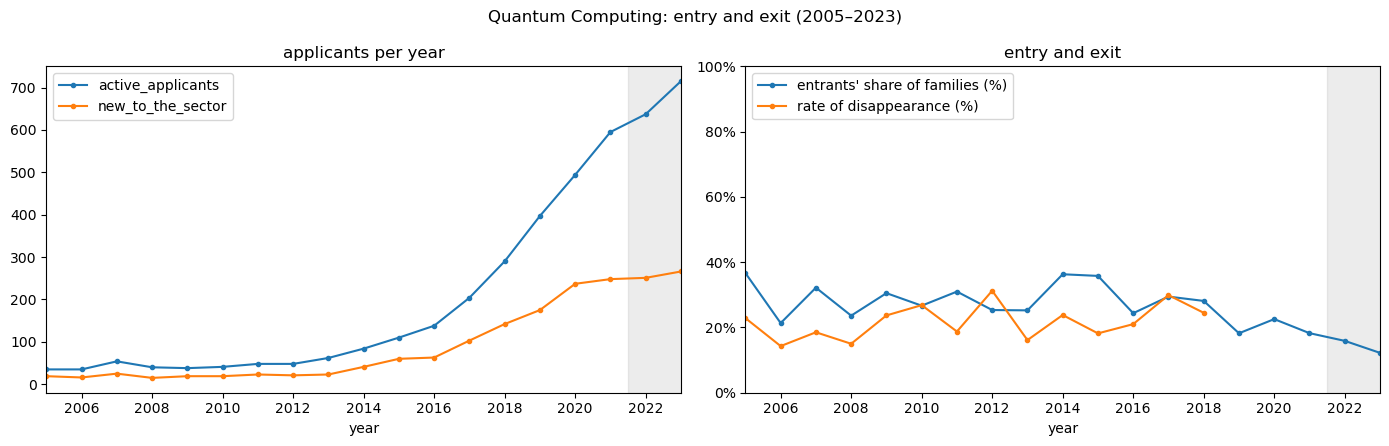

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SECTOR_NAME = "Quantum Computing"
YEAR_MIN = 2005
LAST_COMPLETE_YEAR = 2021
YEAR_MAX = int(df_completo["family_year"].max())

# Deduplicate actor-family links (keep full history to compute true first_year/last_year)
links = (
    df_completo[["harmonized_name_final", "docdb_family_id", "family_year"]]
    .drop_duplicates()
    .rename(columns={
        "harmonized_name_final": "applicant",
        "docdb_family_id": "unit_id",
        "family_year": "year",
    })
)

by_applicant = links.groupby("applicant")
first_year = by_applicant["year"].min()
last_year = by_applicant["year"].max()

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

# Share of each year's families with at least one applicant new to the sector
links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = (
    links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
)

# Filter from 2005 onwards for table and plots
entry_exit = entry_exit.loc[entry_exit.index >= YEAR_MIN]
display(entry_exit.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
entry_exit[["active_applicants", "new_to_the_sector"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="applicants per year", xlabel="year", xlim=(YEAR_MIN, YEAR_MAX))

entry_exit[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="entry and exit", xlabel="year", ylim=(0, 100), xlim=(YEAR_MIN, YEAR_MAX))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))

for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)

fig.suptitle(f"{SECTOR_NAME}: entry and exit (2005–{YEAR_MAX})")
plt.tight_layout()
plt.show()

## Which Subfields go faster? 

Take from step 1 I think

## Pest

## Political
Governments see quantum computing as a strategic technology and fund it directly. In 2018 the US passed the National Quantum Initiative, with near-unanimous support, pledging core government funding of $1.3 billion over five years (US National Quantum Initiative website (quantum.gov)) . In the same year the EU launched its Quantum Technologies Flagship (European Commission, Quantum Technologies Flagship (digital-strategy.ec.europa.eu)). 
Link to our data: Do US and European filings grow faster after 2018? Does the share of universities and public research bodies grow in the same years?


China has supported quantum technology for a long time. Quantum communication and computing were referenced in the 13th Five-Year Plan in 2016, and the 14th Five-Year Plan (2021) named quantum computing again as a frontier technology. Hefei, home of the University of Science and Technology of China (USTC), became the main national hub. (CSIS, Understanding China's Quest for Quantum Advancement.) Link to our data: This is the clearest factor in our data. Origin Quantum (Hefei) is second in the top 15 and entered only in 2017; USTC is the only university in the top 15; Baidu is also a new entrant. We can show China's share of families by year.

US–China technology rivalry --> Quantum is treated as a national security topic. The US Bureau of Industry and Security started a review of controls on emerging technologies, including quantum, already in 2018. This pushes each country to build its own supply chain.
https://www.rusi.org/explore-our-research/publications/commentary/export-controls-accelerate-chinas-quantum-supply-chain

Outlook (after 2023): The US introduced new export controls on quantum computing in September 2024; the EU adopted a Quantum Europe Strategy in 2025; China's 15th Five-Year Plan (2026–2030) identifies quantum technology as the first among seven "future industries". Political support and rivalry are both getting stronger

## Economic

Private money started to flow into quantum start-ups. According to McKinsey, private investment rose from about 0.2 billion in 2019 to roughly $2.1 billion in 2021. Some start-ups, like IonQ, Rigetti and D-Wave, also went public. https://www.mckinsey.com/featured-insights/charts/quantum-investment-surge

Building a quantum computer is very expensive. The OECD notes that due to their complexity and cost, access to quantum computers may be dominated by large technology companies. Concentration by type. Companies are much more concentrated (CR4 27%, Gini 0.82) than universities (CR4 14%), and the top companies (IBM, Google, Microsoft, Fujitsu, Intel) are all incumbents. https://thequantuminsider.com/2025/02/08/governments-face-key-challenges-in-quantum-technology-policy-oecd-report-finds/

Big players buy or merge with smaller ones. IBM bought Red Hat (2019), and Honeywell Quantum Solutions merged with Cambridge Quantum to form Quantinuum (2021).These deals are inside our data. They show that concentration can grow through acquisitions, not only through new patents. This links to the "Consolidate" section.

Outlook (after 2023): Investment exploded. Investment in quantum technology start-ups reached $12.6 billion in 2025, 6.3 times higher than in 2024, and it is concentrated in a few large start-ups https://www.mckinsey.com/featured-insights/charts/quantum-investment-surge

## Social

There are not enough people with quantum skills. The OECD finds that the most pressing weakness lies in quantum algorithms and their use cases, and that it is hard to find people who can connect quantum and classical computing.Weight of universities in the field, and families co-owned by companies and universities (first table). Many co-owned patents mean that firms look for knowledge outside. https://www.oecd.org/en/publications/building-business-readiness-for-quantum-computing_ee847e5f-en/full-report/component-4.html


Quantum start-ups come out of research. An OECD–EPO study finds that more than half of quantum start-up founders hold a PhD, compared with roughly ten percent among founders more broadly.Universities and public research bodies act as a "nursery" for the field: many entrants are spin-offs.

People and governments worry that a future quantum computer could break today's encryption. For this reason NIST started work on post-quantum cryptography back in 2016.https://www.cliffordchance.com/insights/resources/blogs/talking-tech/en/articles/2025/03/quantum-state-of-play.html

## Technological

In 2019 Google's Sycamore chip performed a task that it claimed was beyond classical supercomputers. This made the field visible and attracted money and new players.Google Quantum AI, Nature (2019).

There is no single winning technology: superconducting qubits (IBM, Google, Origin Quantum), trapped ions (IonQ, Quantinuum), quantum annealing (D-Wave), neutral atoms, photonics. Because no design has won yet, new firms can still enter.The top 15 already mixes approaches (D-Wave: annealing; IonQ: ions; IBM: superconducting). 

Qubits make many errors. Error correction is the key problem to solve before quantum computers become useful, and a lot of research focuses on it.

Since IBM put a quantum computer on the cloud in 2016, anyone can test algorithms without owning hardware. This lowers entry barriers for software firms.Software and IT firms among the entrants (Red Hat, Baidu) and the share of software/algorithm families compared with hardware.
Outlook (after 2023): In December 2024 Google reported with the Willow chip that the more qubits it uses, the more it reduces errors, a first real step on error correction. In August 2024 NIST released the first post-quantum cryptography standards.